# FREE-ENERGY PRINCIPLE (FEP) TUTORIAL 5
## Continuous time active Inference
### Controller for a spring mass damper system.

**Author: [Ajith Anil Meera]** Donders Institute for Brain, Cognition and Behaviour. Radboud University. The Netherlands.
Ported to Python and maintained by: **[Pablo Lanillos](http://therobotdecision.com)**, Spanish National Research Council (CSIC)

<font color='green'>**Difficulty: high**</font>

### Date: 31st October 2023
#### Code developed for the Tutorial on Continuous Active Inference at the International Conference on Active Inference IWAI 2023.

Further reading:
- Lanillos, P., Meo, C., Pezzato, C., Meera, A. A., Baioumy, M., Ohata, W., ... & Tani, J. (2021). Active inference in robotics and artificial agents: Survey and challenges. arXiv preprint arXiv:2112.01871.
- Anil Meera, A., & Wisse, M. (2021). Dynamic expectation maximization algorithm for estimation of linear systems with colored noise. Entropy, 23(10), 1306.
- Anil Meera, A., & Lanillos, P. (2023, September). Towards Metacognitive Robot Decision Making for Tool Selection. In International Workshop on Active Inference (pp. 31-42). Cham: Springer Nature Switzerland.


## Description


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import pinv, expm, det
from scipy.signal import cont2discrete # For transforming the Continuous plant to Discrete

In [2]:
# Classes and helper functions


# general linear system in state space equations
class LTI_model():
    def __init__(self, A, B, C, D):
        self.A = A
        self.B = B
        self.C = C
        self.D = D

# Spring mass damper system (SMD) default=(k = .2 m = .4 c = .4)
class SMD(LTI_model):
    def __init__(self, k=.2, m=.4, c=.4, n=2000):
        super(SMD, self).__init__(A=np.array([[0, 1], [-k / m, - c / m]]), B=np.array([[0], [1 / m]]), C=np.array([[1, 0]]), D=np.array([[0]]))
        self.nx = self.A.shape[0]
        self.nu = self.B.shape[1]
        self.ny = self.C.shape[0]
        self.x = np.zeros((self.nx, n))
        self.y = np.zeros((self.ny, n))
        self.u = np.zeros((self.nu, n))  # repmat(1 * sin(.1 * (0:dt:(nt-1) * dt)), nu, 1) # k1 sin(omega * t)

# Brain variables
class BrainAIF:
    def __init__(self, nx, ny, nu):
        self.x = np.zeros((nx,1))
        self.y = np.zeros((ny,1))
        self.Pa = .00001 * np.eye(nu)  # prior precision on action # A = eye(nx)
        self.Pi_w = 10 * np.eye(nx)
        self.k_h = 4
        self.Pi_vel = np.diag([1., 1.]) # prior precision on velocity
        self.Pi_g = np.diag([.01, .01])  # goal precision(gain): tune it with dt for stability of Euler discretization



# Plot controller results
def plot_results(task, system, goal, dt, nt):

    print('Controller: ', task) # Type of controller

    fig, ax = plt.subplots(4, 1)

    ax[0].plot(np.arange(0, (nt - 1)* dt, dt) , system.x[0,:], linewidth=2)
    if task == 'position':
        ax[0].axhline(y=goal[0], linestyle='dashed', color='black', linewidth=2)
    ax[0].set_xlabel('time (s)')
    ax[0].set_ylabel('x')

    ax[1].plot(np.arange(0, (nt - 1)* dt, dt) , system.x[1,:].T,linewidth=2)
    if task == 'velocity':
        ax[1].axhline(y=goal[0], linestyle='dashed', color='black', linewidth=2)
    ax[1].set_xlabel('time (s)')
    ax[1].set_ylabel('$\dot{x}$')

    ax[2].plot(np.arange(dt, (nt - 1)* dt, dt), np.diff(system.x[1,:-1]).T/dt, linewidth=2)
    ax[2].set_xlabel('time (s)')
    ax[2].set_ylabel('$\ddot{x}$')


    ax[3].plot(np.arange(0, (nt - 1)*dt, dt), system.u.T, linewidth=2)
    ax[3].set_xlabel('time (s)')
    ax[3].set_ylabel('u')
    plt.show()

## Task definition
# Spring mass damper system (SMD) *position* control
We want to move the SMD with parameters $(k,c,m)$ to a desired location $\hat{x}$ using a force $u$
![title](img/smd-position.jpg)

In [3]:
task = 'position' # position, velocity, acceleration control
goal = np.array([[.5],[0]]) # desired position and velocity
learn = 1 # learning rate
dt = .01 # sampling time nt = 2000
nt = 2000 # number of time steps

In [4]:
# System definition
system = SMD(n=nt)
sys_d = cont2discrete((system.A, system.B, system.C, system.D), dt)

brain = BrainAIF(nx=system.nx, ny=system.ny, nu=system.nu)

# Partial values of the Variational Free Energy (VFE) for debugging
Ug = 0 # internal energy
Uc = 0 # internal energy
H = 0 # entropy
Pi_u = 0 # precision on action
F_action = 0 # VFE time integral of free energy

## Run active inference controller

In [5]:
for i in range(1, nt-1):
    # assuming a known state
    brain.x = np.asmatrix(system.x[:, i]).T # brain.x = Dx - dFdx Assuming perfect perception
    # Action from FEP (without priors on action):dadt = -dFda = -dFdx * dxda
    # active inference for constant goal state
    # a(:, i) = a(:, i - 1) - learn * ((brain.x - goal_x)'*Pi_g*(-inv(model.A)*model.B) + Pa*a(:,i-1)  )*dt
    brain.k_h = 1
    dFda = (brain.x - goal).T @ brain.Pi_g @ (-pinv(system.A) @ system.B) + brain.Pa @ system.u[:,i-1]
    dFdaa = (-pinv(system.A) @ system.B).T @ brain.Pi_g @ (-pinv(system.A) @ system.B) + brain.Pa

    system.u[:, i] = system.u[:, i - 1] + (expm(-brain.k_h * dFdaa * dt) - np.eye(system.ny)) @ (pinv(dFdaa) @ dFda) # action update from Free energy curve

    Pi_u = dFdaa # precision on action
    Ug = Ug + .5 * (system.x[:, i] - goal).T @ brain.Pi_g @ (system.x[:,i] - goal) # performance
    Uc = Uc + .5 * system.u[:, i].T @ brain.Pa @ system.u[:,i] # control cost
    H = H - .5 * np.log(det(Pi_u)) # confidence

    # Generative process - take action in the real world
    system.x[:, i + 1] = sys_d[0] @ system.x[:, i] + sys_d[1] @ system.u[:, i]
    system.y[:, i] = sys_d[2] @ system.x[:, i] # + .001 * (-1 + 2 * rand(ny, 1))

system.u[:, i + 1] = system.u[:, i] # for plotting purposes one extra value
F_action = F_action + Ug + Uc + H # time integral of free energy

print('\n U^g, U^c,H,F,Pi^u = [#f,#f,#f,#f,#f]\n', Ug, Uc, H, F_action, Pi_u)


 U^g, U^c,H,F,Pi^u = [#f,#f,#f,#f,#f]
 [[2.32891804 0.50050826]
 [0.50050826 2.29047707]] 8.688581968688058e-05 1384.8681075579018 [[1387.19711248 1385.3687027 ]
 [1385.3687027  1387.15867152]] [[0.25001]]


## Plot the results

Controller:  position


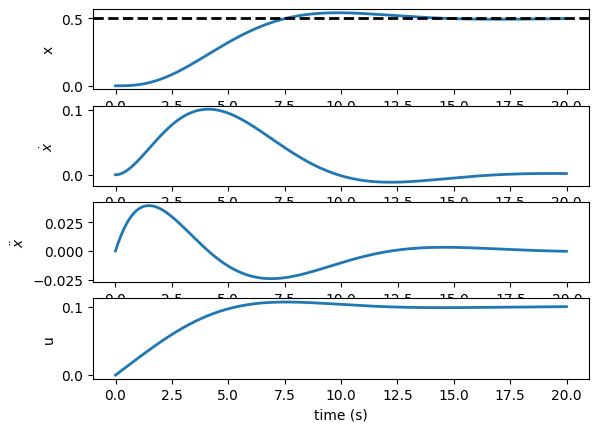

In [6]:
plot_results(task,system,goal,dt,nt)

## Task definition
# Spring mass damper system(SMD) *velocity* control
We want to move the SMD with parameters $(k,c,m)$ with a desired velocity $\hat{\dot{x}}$ using a force $u$
![title](img/smd-velocity.jpg)

In [9]:
task = 'velocity' # position, velocity, acceleration control
goal = np.array([[10],[0]]) # desired goal velocity
learn = 1 # learning rate
dt = .01 # sampling time nt = 2000
nt = 2000 # number of time steps

# System definition
system = SMD(n=nt)
sys_d = cont2discrete((system.A, system.B, system.C, system.D), dt)
brain = BrainAIF(nx=system.nx, ny=system.ny, nu=system.nu)

# Partial values of the Variational Free Energy (VFE) for debugging
Ug = 0 # internal energy
Uc = 0 # internal energy
H = 0 # entropy
Pi_u = 0 # precision on action
F_action = 0 # VFE time integral of free energy

## Run active inference controller

In [11]:
for i in range(1, nt-1):
    # assuming a known state
    brain.x = np.asmatrix(system.x[:, i]).T # brain.x = Dx - dFdx Assuming perfect perception
    # Action from FEP (without priors on action):dadt = -dFda = -dFdx * dxda
    # active inference for constant goal state velocity

    dFda = (system.A @ np.ones((system.nx, system.nu)) + system.B).T @ brain.Pi_vel @ \
           (system.A @ brain.x + system.B @ np.asmatrix(system.u[:, i - 1]) - goal) + brain.Pa @ system.u[:, i - 1]

    dFdaa = (system.A @ np.ones((system.nx, system.nu)) + system.B).T @ brain.Pi_vel @ (system.A @ np.ones((system.nx,system.nu))+system.B) + brain.Pa

    system.u[:, i] = system.u[:, i - 1] + (expm(-brain.k_h * dFdaa * dt) - np.eye(system.nu)) @ (pinv(dFdaa) @ dFda) # action update from Free energy curve
    Pi_u = dFdaa  # precision on action
    Ug = Ug + .5 * (np.array([[system.x[1, i]], [(system.x[1, i] - system.x[1, i - 1])/ dt]]) - goal).T @ \
                    brain.Pi_vel @ ([[system.x[1, i]], [(system.x[1, i] - system.x[1, i - 1]) / dt]] - goal)
    Uc = Uc + .5 * system.u[:, i].T @ brain.Pa @ system.u[:,i]    # control cost
    H = H - .5 * np.log(det(Pi_u))  # Confidence

    # Generative process - take action in the world
    system.x[:, i + 1] = sys_d[0] @ system.x[:, i] + sys_d[1] @ system.u[:, i]
    system.y[:, i] = sys_d[2] @ system.x[:, i] # + .001 * (-1 + 2 * rand(ny, 1))

system.u[:, i + 1] = system.u[:, i] # for plotting purposes one extra value
F_action = F_action + Ug + Uc + H # time integral of free energy

print('\n U^g, U^c,H,F,Pi^u = [#f,#f,#f,#f,#f]\n', Ug, Uc, H, F_action, Pi_u)


 U^g, U^c,H,F,Pi^u = [#f,#f,#f,#f,#f]
 [[5492.81670023]] 5.562398101038104 -692.805604457195 [[4805.57349387]] [[2.00001]]


## Plot the results

Controller:  velocity


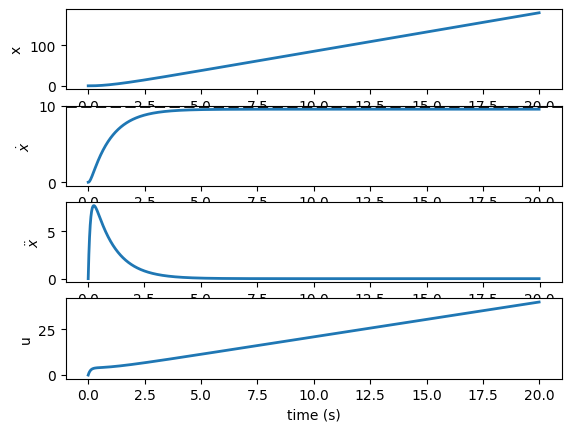

In [12]:
plot_results(task, system, goal, dt, nt)